# Diviser pour régner — Exercice 6 : paver une grille avec des triominos (correction)

Ce notebook contient, pour chaque question, trois blocs **toujours séparés** :

| Bloc | Contenu |
|:---|:---|
| 📝 **ÉNONCÉ** | la question, recopiée du sujet |
| ✅ **RÉSOLUTION** | la réponse attendue (code et/ou texte) |
| 💡 **EXPLICATION PÉDAGOGIQUE** | pourquoi ça marche, le lien avec le cours, les erreurs à éviter. **N'est pas à recopier.** |

**Notions travaillées :** récursivité sur une grille, découpage en 4, raisonnement par récurrence.

Exécuter les cellules **dans l'ordre** (*Cell → Run All*).

> **Principe (cours)** — La méthode « diviser pour régner » (*divide and conquer*) consiste à « diviser » un problème en sous-problèmes indépendants dont les solutions sont recombinées :
> - on décompose le problème en sous-problèmes ;
> - on résout chaque sous-problème ;
> - on fusionne les solutions des sous-problèmes en une solution globale.

---
# EXERCICE 6

#### 📝 ÉNONCÉ

> Sur une grille carrée comportant $2^n \times 2^n$ cases, on souhaite disposer les motifs ci-dessous pour qu'ils recouvrent la grille, à l'exception d'une seule case (il n'est pas possible de recouvrir parfaitement la grille avec ces motifs).
>
> 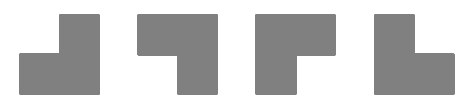
>
> Exemple de recouvrement avec $n = 3$.
>
> 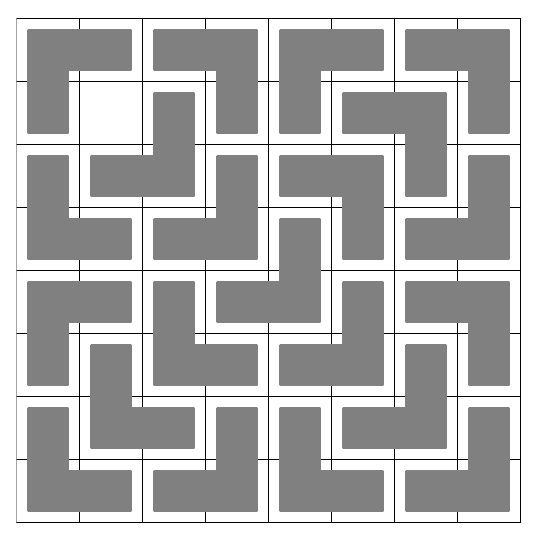
>
> Écrire un algorithme récursif s'appuyant sur une stratégie « diviser pour régner » qui permette, étant donnée une case repérée par ses coordonnées (i, j), de recouvrir un échiquier carré de dimensions $2^k \times 2^k$ par les motifs ci-dessus.

#### ✅ RÉSOLUTION

**L'algorithme (en français) :** pour paver un carré de côté $2^k$ dont une case est déjà occupée :
1. **Cas de base :** si le carré a un côté 1, il n'y a rien à faire.
2. On coupe le carré en **4 sous-carrés** de côté $2^{k-1}$.
3. On pose **un triomino au centre**, sur les 3 cases qui touchent le centre et qui sont dans les 3 sous-carrés **ne contenant pas** la case occupée.
4. Chaque sous-carré a maintenant exactement une case occupée : on les pave **récursivement**.

**Le programme :**

In [1]:
def pavage(k, i, j):
    # renvoie une grille 2^k x 2^k : 0 = case laissée vide, sinon numéro du triomino
    n = 2 ** k
    grille = [[0] * n for _ in range(n)]
    compteur = [0]                      # liste pour pouvoir le modifier dans la fonction interne

    def pave(lig, col, taille, vi, vj):
        # pave le carré de coin haut-gauche (lig, col), de côté taille,
        # dont la case (vi, vj) est déjà occupée
        if taille == 1:
            return                      # cas de base : rien à faire
        m = taille // 2
        compteur[0] += 1
        num = compteur[0]
        # les 4 sous-carrés et, pour chacun, sa case qui touche le centre
        sous_carres = [
            (lig,     col,     lig + m - 1, col + m - 1),   # haut-gauche
            (lig,     col + m, lig + m - 1, col + m),       # haut-droite
            (lig + m, col,     lig + m,     col + m - 1),   # bas-gauche
            (lig + m, col + m, lig + m,     col + m),       # bas-droite
        ]
        for (l0, c0, cl, cc) in sous_carres:
            if l0 <= vi < l0 + m and c0 <= vj < c0 + m:
                pave(l0, c0, m, vi, vj)             # contient déjà la case occupée
            else:
                grille[cl][cc] = num                # un morceau du triomino central
                pave(l0, c0, m, cl, cc)             # cette case devient la case occupée

    pave(0, 0, n, i, j)
    return grille


def affiche(grille):
    symboles = "ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789"
    for ligne in grille:
        print(" ".join("·" if v == 0 else symboles[(v - 1) % len(symboles)] for v in ligne))


g = pavage(3, 1, 1)       # même case vide que dans l'exemple de l'énoncé
affiche(g)

C C D D H H I I
C · B D H G G I
E B B F J J G K
E E F F A J K K
M M N A A R S S
M L N N R R Q S
O L L P T Q Q U
O O P P T T U U


#### 💡 EXPLICATION PÉDAGOGIQUE

(L'énoncé écrit $2^n$ puis $2^k$ : c'est la même chose, on utilise $k$.)

**L'idée clé :**
- La case interdite se trouve dans **une seule** des 4 sous-grilles. Les 3 autres sont « pleines », donc on ne peut pas encore leur appliquer la récursion, qui a besoin d'une case occupée.
- **L'astuce :** le triomino posé au centre occupe **une case de chacune des 3 autres sous-grilles**. Maintenant, **chacune des 4 sous-grilles a exactement une case occupée** : c'est le même problème en plus petit !

```
 ┌─────────┬─────────┐       ┌─────────┬─────────┐
 │         │         │       │         │         │
 │    X    │         │       │    X    │         │
 │         │         │  -->  │         │#        │
 ├─────────┼─────────┤       ├─────────┼─────────┤
 │         │         │       │        #│#        │
 │         │         │       │         │         │
 └─────────┴─────────┘       └─────────┴─────────┘
  X = case interdite          # = triomino posé au centre
```

**Lecture de l'affichage :** chaque lettre correspond à un triomino ; les 3 cases portant la même lettre forment un **L**. Le point `·` est la case laissée vide, en `(1, 1)` comme sur la figure de l'énoncé.

**Vérification du nombre de pièces :** la grille a $4^k$ cases et on en laisse une vide, donc il faut $(4^k - 1)/3$ triominos. Pour $k = 3$ : $63 / 3 = 21$ triominos.

**Détails du programme (non exigibles) :** la fonction `pave` est définie **à l'intérieur** de `pavage`, et `compteur` est une liste pour pouvoir être modifiée depuis `pave`. Sur une copie, l'algorithme en français ci-dessus suffit souvent.

*Vérification automatique (non demandée) : toutes les positions de la case vide, pour des grilles jusqu'à 32 × 32.*

In [2]:
def verifie(grille, i, j):
    n = len(grille)
    positions = {}
    for l in range(n):
        for c in range(n):
            positions.setdefault(grille[l][c], []).append((l, c))
    assert positions[0] == [(i, j)]
    for num, cases in positions.items():
        if num == 0:
            continue
        assert len(cases) == 3
        lignes = [l for l, c in cases]
        colonnes = [c for l, c in cases]
        assert max(lignes) - min(lignes) == 1 and max(colonnes) - min(colonnes) == 1
    assert len(positions) - 1 == (n * n - 1) // 3


for k in range(1, 6):
    n = 2 ** k
    for i in range(n):
        for j in range(n):
            verifie(pavage(k, i, j), i, j)
print("Tous les pavages sont corrects ✔")

Tous les pavages sont corrects ✔


In [3]:
affiche(pavage(4, 10, 3))     # une grille 16 x 16, case vide en (10, 3)

D D E E I I J J Y Y Z Z d d e e
D C C E I H H J Y X X Z d c c e
F C G G K K H L a X b b f f c g
F F G B B K L L a a b W W f g g
N N O B S S T T i i j j W n o o
N M O O S R R T i h h j n n m o
P M M Q U R V V k k h l p m m q
P P Q Q U U V A A k l l p p q q
t t u u y y z z A E F F J J K K
t s s u y x x z E E D F J I I K
v s w · 0 0 x 1 G D D H L L I M
v v w w r 0 1 1 G G H H C L M M
3 3 4 r r 8 9 9 O O P C C T U U
3 2 4 4 8 8 7 9 O N P P T T S U
5 2 2 6 A 7 7 B Q N N R V S S W
5 5 6 6 A A B B Q Q R R V V W W


#### 💡 EXPLICATION PÉDAGOGIQUE

**Pourquoi c'est du « diviser pour régner » ?**
- **diviser** : 4 sous-grilles de côté deux fois plus petit ;
- **régner** : 4 appels récursifs sur des problèmes **de même nature** (une grille avec une case occupée) ;
- **combiner** : rien à faire, sauf le triomino central posé avant les appels.

Cette démonstration prouve aussi qu'un tel pavage **existe toujours**, quelle que soit la case retirée : c'est un raisonnement **par récurrence**.